# Дообучение `deepvk/USER-bge-m3` на банковских документах

Двухэтапный пайплайн:

```
Этап 1 — TSDAE (unsupervised)          Этап 2 — MNRL / TripletLoss (supervised)
────────────────────────────           ─────────────────────────────────────────
data_test/stage1_tsdae/                data_test/stage2_supervised/
  corpus.csv  (75 чанков)                train.csv  (47 триплетов)
                                          eval.csv   (12 триплетов)

Corrupted(text) → Encoder               anchor  → ┐
                       ↓                positive → ├─ Loss → градиент
                  Decoder → text         negative → ┘
```

Оба этапа используют **реальные** тестовые данные из `data_test/`.

In [1]:
!nvidia-smi

Wed Mar 25 09:30:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.02              Driver Version: 560.94         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060        On  |   00000000:01:00.0  On |                  N/A |
|  0%   44C    P8             11W /  170W |     253MiB /  12288MiB |      5%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 0. Окружение

In [2]:
import sys, os, warnings, logging, re
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

from src import EmbeddingTrainer, LossType
from src.trainer import make_cpu_config, make_gpu_config
from src.metrics import RetrievalEvaluator, build_evaluation_set

DATA = Path("../data_test")
OUT  = Path("../output");  OUT.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "deepvk/USER-bge-m3"

# ═══════════════════════════════════════════════════════════════════════════════
# ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ ОБУЧЕНИЯ — менять здесь, не трогая ячейки с конфигами
# ═══════════════════════════════════════════════════════════════════════════════
NUM_EPOCHS_TSDAE       = 10    # кол-во эпох для этапа 1 (unsupervised TSDAE)
NUM_EPOCHS_SUPERVISED  = 10    # кол-во эпох для этапов 2+ (Triplet / MNRL)
EARLY_STOPPING_PATIENCE = 2    # остановить обучение если N эпох нет улучшения (0 = выкл.)
LOG_EVERY               = "epoch"  # "epoch" — каждую эпоху; "steps" — по logging_steps
# ═══════════════════════════════════════════════════════════════════════════════

print(f"Устройство: {DEVICE}")
print(f"PyTorch: {torch.__version__}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"\nПараметры обучения:")
print(f"  NUM_EPOCHS_TSDAE        = {NUM_EPOCHS_TSDAE}")
print(f"  NUM_EPOCHS_SUPERVISED   = {NUM_EPOCHS_SUPERVISED}")
print(f"  EARLY_STOPPING_PATIENCE = {EARLY_STOPPING_PATIENCE}")
print(f"  LOG_EVERY               = {LOG_EVERY!r}")

2026-03-25 09:31:00,786 | INFO | PyTorch version 2.6.0+cu124 available.
2026-03-25 09:31:00,992 | INFO | Loading faiss with AVX2 support.
2026-03-25 09:31:01,019 | INFO | Successfully loaded faiss with AVX2 support.


Устройство: cuda
PyTorch: 2.6.0+cu124
GPU: NVIDIA GeForce RTX 3060

Параметры обучения:
  NUM_EPOCHS_TSDAE        = 10
  NUM_EPOCHS_SUPERVISED   = 10
  EARLY_STOPPING_PATIENCE = 2
  LOG_EVERY               = 'epoch'


---
# ЭТАП 1 — TSDAE: доменная адаптация без разметки

**Идея:** учим модель восстанавливать исходный текст из зашумлённой версии.  
Никаких лейблов не нужно — только сырые чанки из банковских документов.

```
"Льготный период по карте составляет до 55 дней"
         ↓  noise_ratio=0.6 (удаляем ~60% слов)
"период карте 55"
         ↓  Encoder → эмбеддинг
         ↓  Decoder → reconstruct
"Льготный период по карте составляет до 55 дней"  ← цель
```

Модель вынуждена выучить семантику банковских терминов, чтобы восстанавливать текст из 2–3 слов.

## 1.1 Загрузка корпуса

In [3]:
corpus_df = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")

print(f"Чанков в корпусе: {len(corpus_df)}")
print(f"Колонки: {corpus_df.columns.tolist()}\n")

corpus_df["n_words"] = corpus_df["sentence"].str.split().str.len()
corpus_df[["sentence", "n_words"]].head(10)

Чанков в корпусе: 101
Колонки: ['sentence', 'doc_id', 'section', 'chunk_id']



,sentence,n_words
0,Ипотечное кредитование — долгосрочный банковск...,18
1,Процентная ставка по ипотеке определяется инди...,23
2,"Первоначальный взнос — сумма, которую заёмщик ...",22
3,Страхование при ипотеке является обязательным:...,26
4,Досрочное погашение ипотеки разрешено без штра...,28
5,Рефинансирование ипотеки позволяет снизить тек...,20
6,Льготная ипотека с государственной поддержкой ...,27
7,Эскроу-счёт при покупке строящегося жилья (ДДУ...,29
8,Автокредит — целевой банковский кредит на поку...,21
9,Процентная ставка по автокредиту зависит от пе...,31


In [4]:
# ── Генерация corpus.csv из расширенного банковского корпуса ──────────────────
# Запускать при первом запуске или после обновления _BANKING_CORPUS в data_preparation.py
from src.data_preparation import generate_sample_banking_chunks, DocumentChunker

chunker = DocumentChunker(chunk_size=256, overlap=0, split_by="paragraph")
all_chunks = generate_sample_banking_chunks(chunker=chunker)

corpus_out = DATA / "stage1_tsdae"
corpus_out.mkdir(parents=True, exist_ok=True)

corpus_csv = pd.DataFrame([
    {"sentence": c.text, "doc_id": c.doc_id, "section": c.section, "chunk_id": c.chunk_id}
    for c in all_chunks
])
corpus_csv.to_csv(corpus_out / "corpus.csv", index=False, encoding="utf-8")

print(f"Сгенерировано чанков  : {len(corpus_csv)}")
print(f"Документов            : {corpus_csv['doc_id'].nunique()}")
print(f"Тематических разделов : {corpus_csv['section'].nunique()}")
print(f"Сохранено в           : {corpus_out / 'corpus.csv'}")
corpus_csv["section"].value_counts()

2026-03-25 09:31:01,101 | INFO | Сгенерировано 101 чанков из 16 документов


Сгенерировано чанков  : 101
Документов            : 16
Тематических разделов : 16
Сохранено в           : ../data_test/stage1_tsdae/corpus.csv


section
Ипотека                           8
Потребительские кредиты           7
Вклады                            7
Банковские карты                  7
Автокредитование                  6
Кредиты для бизнеса               6
Накопительные счета               6
Страхование имущества             6
Страхование жизни                 6
Брокерское обслуживание           6
Расчётно-кассовое обслуживание    6
Факторинг                         6
Банковские гарантии               6
Лизинг                            6
Цифровые банковские сервисы       6
Валютные операции                 6
Name: count, dtype: int64

## 1.2 EDA корпуса

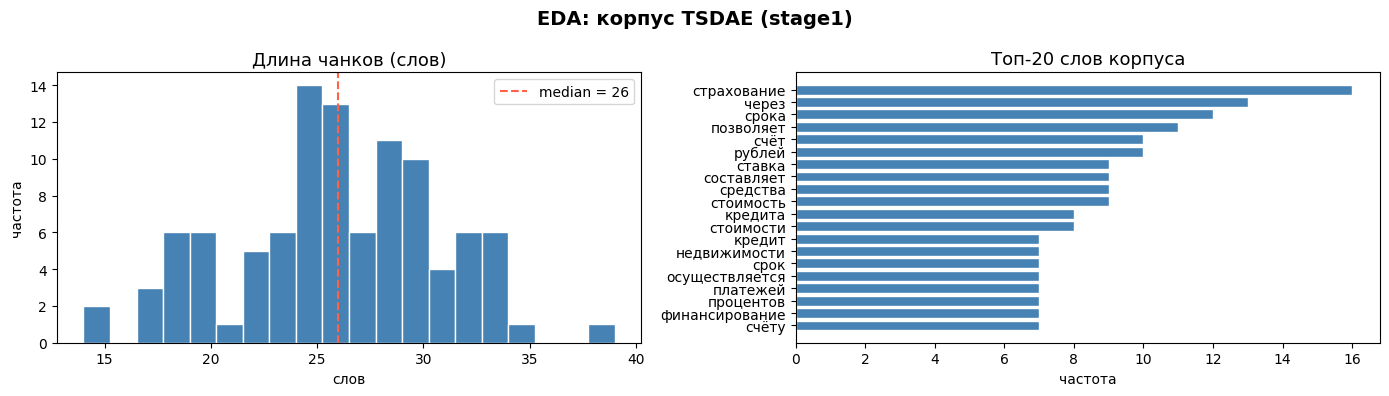


Средняя длина чанка : 25.8 слов
Уникальных слов     : 1301


In [5]:
# Распределение длин + топ-слова
from collections import Counter

STOPWORDS = {"и","в","на","по","от","до","или","для","при","не","а",
             "к","с","из","за","как","то","что","это","но","если",
             "о","об","со","под","его","её","их","также","только"}

all_words = [
    w.lower().strip(".,;:—()\"«»") 
    for s in corpus_df["sentence"] 
    for w in s.split() 
    if w.lower().strip(".,;:—()\"«»") not in STOPWORDS and len(w) > 3
]
top_words = Counter(all_words).most_common(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Длины
ax1.hist(corpus_df["n_words"], bins=20, color="steelblue", edgecolor="white")
ax1.axvline(corpus_df["n_words"].median(), color="tomato", linestyle="--",
            label=f'median = {corpus_df["n_words"].median():.0f}')
ax1.set_title("Длина чанков (слов)", fontsize=13)
ax1.set_xlabel("слов"); ax1.set_ylabel("частота")
ax1.legend()

# Топ слова
words, counts = zip(*top_words)
ax2.barh(words[::-1], counts[::-1], color="steelblue", edgecolor="white")
ax2.set_title("Топ-20 слов корпуса", fontsize=13)
ax2.set_xlabel("частота")

plt.suptitle("EDA: корпус TSDAE (stage1)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nСредняя длина чанка : {corpus_df['n_words'].mean():.1f} слов")
print(f"Уникальных слов     : {len(set(all_words))}")

## 1.3 Визуализация процесса шумирования (что именно видит модель)

In [6]:
import random
random.seed(42)

def add_noise(text: str, noise_ratio: float = 0.6) -> str:
    """Удаляем случайные слова — имитируем TSDAE corruption."""
    words = text.split()
    kept = [w for w in words if random.random() > noise_ratio]
    return " ".join(kept) if kept else words[0]

# Показываем на реальных примерах из corpus.csv
sample_sentences = corpus_df["sentence"].sample(6, random_state=42).tolist()

print("Примеры шумирования (noise_ratio = 0.6):\n")
print(f"{'ОРИГИНАЛ':<65}  →  ЗАШУМЛЁННЫЙ ВХОД ДЛЯ МОДЕЛИ")
print("─" * 110)
for s in sample_sentences:
    noised = add_noise(s, noise_ratio=0.6)
    orig_words  = len(s.split())
    kept_words  = len(noised.split())
    print(f"{s[:63]:<65}  →  {noised}")
    print(f"  {'':65}     [{kept_words}/{orig_words} слов оставлено]")
    print()

Примеры шумирования (noise_ratio = 0.6):

ОРИГИНАЛ                                                           →  ЗАШУМЛЁННЫЙ ВХОД ДЛЯ МОДЕЛИ
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
Финансовый лизинг отличается от аренды: по окончании договора л    →  Финансовый аренды: по окончании (обычно цены). в течение числится
                                                                        [9/28 слов оставлено]

Инвестиционное страхование жизни (ИСЖ) — продукт с защитой влож    →  Инвестиционное страхование жизни (ИСЖ) продукт вложенного капитала и в 100% портфеля.
                                                                        [11/26 слов оставлено]

Открытие расчётного счёта ИП и ООО осуществляется на основании     →  Открытие расчётного ИП осуществляется на пакета документов: паспорт, решение об общества. счёта 1
                                                                        [13/31 слов оставлено]

Ин

In [7]:
# Как noise_ratio влияет на количество оставшихся слов
ratios = [0.3, 0.5, 0.6, 0.7, 0.8]
example = corpus_df["sentence"].iloc[1]  # фиксированный пример

print(f"Пример: \"{example}\"\n")
print(f"{'noise_ratio':<14} {'оставлено слов':<18} {'зашумлённый текст'}")
print("─" * 90)
for r in ratios:
    random.seed(42)
    n = add_noise(example, noise_ratio=r)
    kept = len(n.split())
    total = len(example.split())
    bar = "█" * kept + "░" * (total - kept)
    print(f"{r:<14} {kept}/{total} {bar:<20}  {n}")

Пример: "Процентная ставка по ипотеке определяется индивидуально для каждого заёмщика
и зависит от размера первоначального взноса, срока кредита, кредитной истории
и программы государственного субсидирования."

noise_ratio    оставлено слов     зашумлённый текст
──────────────────────────────────────────────────────────────────────────────────────────
0.3            13/23 █████████████░░░░░░░░░░  Процентная определяется индивидуально для заёмщика от взноса, срока кредитной истории программы государственного субсидирования.
0.5            11/23 ███████████░░░░░░░░░░░░  Процентная определяется индивидуально для от взноса, срока кредитной истории программы государственного
0.6            8/23 ████████░░░░░░░░░░░░░░░  Процентная определяется индивидуально для взноса, истории программы государственного
0.7            4/23 ████░░░░░░░░░░░░░░░░░░░  определяется для истории программы
0.8            3/23 ███░░░░░░░░░░░░░░░░░░░░  для истории программы


## 1.4 Обучение — Этап 1 (TSDAE)

In [8]:
# Готовим DataFrame для тренера: нужна колонка anchor (= исходный текст)
stage1_df = corpus_df[["sentence"]].rename(columns={"sentence": "anchor"})

print(f"Строк для TSDAE: {len(stage1_df)}")
stage1_df.head(5)

Строк для TSDAE: 101


,anchor
0,Ипотечное кредитование — долгосрочный банковск...
1,Процентная ставка по ипотеке определяется инди...
2,"Первоначальный взнос — сумма, которую заёмщик ..."
3,Страхование при ипотеке является обязательным:...
4,Досрочное погашение ипотеки разрешено без штра...


In [9]:
if DEVICE == "cpu":
    cfg_tsdae = make_cpu_config(
        loss_type=LossType.TSDAE,
        num_epochs=NUM_EPOCHS_TSDAE,
        output_dir="../output/stage1_tsdae",
    )
else:
    cfg_tsdae = make_gpu_config(
        loss_type=LossType.TSDAE,
        num_epochs=NUM_EPOCHS_TSDAE,
        output_dir="../output/stage1_tsdae",
    )

cfg_tsdae.tsdae_noise_ratio         = 0.65
cfg_tsdae.early_stopping_patience   = EARLY_STOPPING_PATIENCE
cfg_tsdae.logging_strategy          = LOG_EVERY

print("Конфигурация TSDAE (этап 1 — unsupervised):")
print(f"  model                    : {cfg_tsdae.model_name}")
print(f"  loss                     : {cfg_tsdae.loss_type}")
print(f"  noise_ratio              : {cfg_tsdae.tsdae_noise_ratio}")
print(f"  num_epochs               : {cfg_tsdae.num_epochs}")
print(f"  early_stopping_patience  : {cfg_tsdae.early_stopping_patience}")
print(f"  logging_strategy         : {cfg_tsdae.logging_strategy!r}")
print(f"  batch_size               : {cfg_tsdae.batch_size}")
print(f"  learning_rate            : {cfg_tsdae.learning_rate}")

Конфигурация TSDAE (этап 1 — unsupervised):
  model                    : deepvk/USER-bge-m3
  loss                     : LossType.TSDAE
  noise_ratio              : 0.65
  num_epochs               : 10
  early_stopping_patience  : 2
  logging_strategy         : 'epoch'
  batch_size               : 32
  learning_rate            : 2e-05


In [10]:
trainer_tsdae = EmbeddingTrainer(cfg_tsdae)

2026-03-25 09:31:02,743 | INFO | Устройство: cuda
2026-03-25 09:31:02,744 | INFO | GPU: включён bf16
2026-03-25 09:31:02,745 | INFO | Загрузка модели: deepvk/USER-bge-m3
2026-03-25 09:31:02,751 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-25 09:31:05,634 | INFO | Модель загружена. max_seq_length=512


In [11]:
trainer_tsdae.train(stage1_df)  # eval не нужен — unsupervised

2026-03-25 09:31:05,639 | INFO | Подготовка датасета: 101 обучающих строк, loss=LossType.TSDAE
Some weights of XLMRobertaForCausalLM were not initialized from the model checkpoint at deepvk/USER-bge-m3 and are newly initialized: ['lm_head.bias', 'lm_head.decoder.bias', 'lm_head.dense.bias', 'lm_head.dense.weight', 'lm_head.layer_norm.bias', 'lm_head.layer_norm.weight', 'roberta.encoder.layer.0.crossattention.output.LayerNorm.bias', 'roberta.encoder.layer.0.crossattention.output.LayerNorm.weight', 'roberta.encoder.layer.0.crossattention.output.dense.bias', 'roberta.encoder.layer.0.crossattention.output.dense.weight', 'roberta.encoder.layer.0.crossattention.self.key.bias', 'roberta.encoder.layer.0.crossattention.self.key.weight', 'roberta.encoder.layer.0.crossattention.self.query.bias', 'roberta.encoder.layer.0.crossattention.self.query.weight', 'roberta.encoder.layer.0.crossattention.self.value.bias', 'roberta.encoder.layer.0.crossattention.self.value.weight', 'roberta.encoder.layer.1.c

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

2026-03-25 09:31:08,340 | INFO | Старт обучения: epochs=10, batch=32, lr=2e-05, device=cuda, early_stop_patience=2, logging=epoch
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


Step,Training Loss
4,19.555500
8,13.745800
12,11.188900
16,9.949100
20,9.259100
24,8.819900
28,8.748300
32,8.417500
36,8.330800
40,8.316000


2026-03-25 09:31:15,461 | INFO | Epoch 1/10 [train] | loss=19.5555 | lr=2.00e-05
2026-03-25 09:31:15,465 | INFO | Save model to ../output/stage1_tsdae/best_unsupervised
2026-03-25 09:31:20,901 | INFO | EarlyStopping [train] epoch=1: loss=19.5555 ↓ (best saved → ../output/stage1_tsdae/best_unsupervised)
2026-03-25 09:31:20,905 | INFO | Saving model checkpoint to ../output/stage1_tsdae/checkpoint-4
2026-03-25 09:31:20,908 | INFO | Save model to ../output/stage1_tsdae/checkpoint-4
2026-03-25 09:31:53,625 | INFO | Epoch 2/10 [train] | loss=13.7458 | lr=1.78e-05
2026-03-25 09:31:53,631 | INFO | Save model to ../output/stage1_tsdae/best_unsupervised
2026-03-25 09:31:58,734 | INFO | EarlyStopping [train] epoch=2: loss=13.7458 ↓ (best saved → ../output/stage1_tsdae/best_unsupervised)
2026-03-25 09:31:58,737 | INFO | Saving model checkpoint to ../output/stage1_tsdae/checkpoint-8
2026-03-25 09:31:58,741 | INFO | Save model to ../output/stage1_tsdae/checkpoint-8
2026-03-25 09:32:32,148 | INFO | E

## 1.5 Что изменилось в эмбеддингах после TSDAE?

Смотрим на матрицу косинусного сходства между чанками **до** и **после** дообучения.  
Ожидаем: модель должна лучше различать чанки разных тематик.

2026-03-25 09:37:36,166 | INFO | Use pytorch device_name: cuda
2026-03-25 09:37:36,166 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-25 09:37:39,549 | INFO | Use pytorch device_name: cuda
2026-03-25 09:37:39,549 | INFO | Load pretrained SentenceTransformer: ../output/stage1_tsdae/best_unsupervised


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

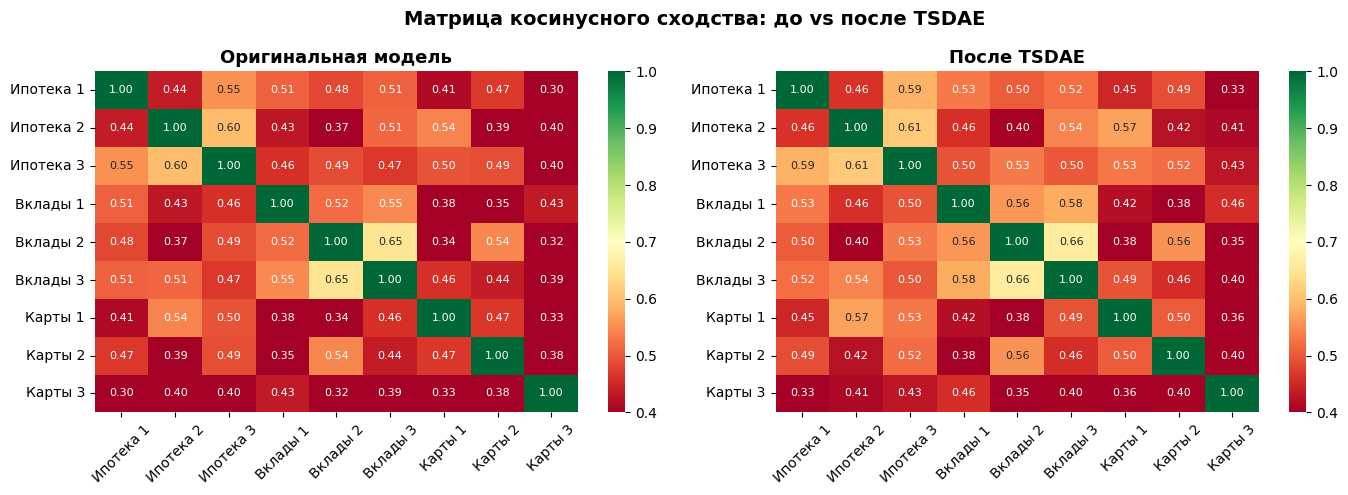

Оригинал    внутри темы: 0.498   между темами: 0.437   разрыв: 0.061
TSDAE       внутри темы: 0.525   между темами: 0.464   разрыв: 0.061


In [12]:
# Берём по 3 чанка из разных тематик для наглядности
sample_texts = [
    # Ипотека
    "Первоначальный взнос по ипотеке составляет не менее 15% от стоимости объекта недвижимости.",
    "Досрочное погашение ипотеки осуществляется без штрафных санкций.",
    "Рефинансирование ипотечного кредита позволяет снизить действующую процентную ставку.",
    # Вклады
    "Система страхования вкладов обеспечивает возмещение средств до 1 400 000 рублей.",
    "Вклад с капитализацией процентов предусматривает начисление процентов на ранее начисленные.",
    "Процентная ставка по вкладу фиксируется на весь срок размещения.",
    # Карты
    "Льготный беспроцентный период по кредитной карте составляет до 55 дней.",
    "Снятие наличных с кредитной карты сопровождается комиссией и начислением процентов.",
    "Технология 3D Secure обеспечивает дополнительную защиту онлайн-платежей.",
]
labels = [
    "Ипотека 1", "Ипотека 2", "Ипотека 3",
    "Вклады 1",  "Вклады 2",  "Вклады 3",
    "Карты 1",   "Карты 2",   "Карты 3",
]

model_orig  = SentenceTransformer(MODEL_NAME)
model_tsdae = SentenceTransformer("../output/stage1_tsdae/best_unsupervised")

emb_orig  = model_orig.encode(sample_texts,  normalize_embeddings=True)
emb_tsdae = model_tsdae.encode(sample_texts, normalize_embeddings=True)

sim_orig  = cosine_similarity(emb_orig)
sim_tsdae = cosine_similarity(emb_tsdae)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
kw = dict(vmin=0.4, vmax=1.0, cmap="RdYlGn", annot=True, fmt=".2f",
          annot_kws={"size": 8}, xticklabels=labels, yticklabels=labels)

sns.heatmap(sim_orig,  ax=axes[0], **kw)
axes[0].set_title("Оригинальная модель", fontsize=13, fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(sim_tsdae, ax=axes[1], **kw)
axes[1].set_title("После TSDAE", fontsize=13, fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Матрица косинусного сходства: до vs после TSDAE",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/stage1_similarity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Среднее сходство внутри темы vs между темами
for name, sim in [("Оригинал", sim_orig), ("TSDAE", sim_tsdae)]:
    intra = np.mean([sim[i,j] for i in range(9) for j in range(9)
                     if i != j and i//3 == j//3])
    inter = np.mean([sim[i,j] for i in range(9) for j in range(9)
                     if i//3 != j//3])
    print(f"{name:10s}  внутри темы: {intra:.3f}   между темами: {inter:.3f}   "
          f"разрыв: {intra-inter:.3f}")

---
# ЭТАП 2 — Supervised Fine-tuning: триплеты (anchor, positive, negative)

Теперь обучаем модель явно различать **релевантные** и **нерелевантные** пары.  
Используем размеченные триплеты из `data_test/stage2_supervised/`.

```
anchor   = пользовательский запрос
positive = правильный ответ-чанк (100% релевантен)
negative = похожий, но неправильный чанк (hard negative из смежной темы)
```

## 2.1 Загрузка триплетов

In [13]:
from src.data_preparation import Chunk, TripletSampler

# Загружаем корпус из этапа 1 (doc_id и section теперь хранятся в CSV явно)
corpus_df = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")

# Создаём Chunk-объекты, используя реальные doc_id и section из корпуса
chunks = [
    Chunk(
        text=row["sentence"],
        doc_id=row["doc_id"],
        chunk_id=row["chunk_id"],
        section=row["section"],
    )
    for row in corpus_df.to_dict("records")
]

print(f"Чанков всего   : {len(chunks)}")
print(f"Документов     : {len(set(c.doc_id for c in chunks))}")
print(f"Секций         : {len(set(c.section for c in chunks))}")

# Формируем триплеты (bm25 hard negatives) по всем трём стратегиям
sampler = TripletSampler(chunks, negative_strategy="bm25", seed=42)
all_df  = sampler.to_dataframe(strategies=["adjacent", "section", "query_template"],
                                n_per_chunk=2)

print(f"\nВсего триплетов: {len(all_df)}")
print(all_df["strategy"].value_counts().to_string())

# Split 80/20 train/eval
from sklearn.model_selection import train_test_split
train_df, eval_df = train_test_split(all_df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
eval_df  = eval_df.reset_index(drop=True)

print(f"\nTrain: {len(train_df)}  |  Eval: {len(eval_df)}")

2026-03-25 09:37:45,553 | INFO | BM25HardNegativeMiner инициализирован на 101 чанках
2026-03-25 09:37:45,554 | INFO | TripletSampler: 101 чанков, 16 документов, стратегия=bm25
2026-03-25 09:37:45,625 | INFO | adjacent: сформировано 202 триплетов
2026-03-25 09:37:45,690 | INFO | section: сформировано 202 триплетов


Чанков всего   : 101
Документов     : 16
Секций         : 16


2026-03-25 09:37:45,731 | INFO | query_template: сформировано 202 триплетов
2026-03-25 09:37:45,735 | INFO | Дедупликация: 606 -> 470 триплетов
2026-03-25 09:37:45,737 | INFO | Итого триплетов: 470  (стратегии: {'query_template': 197, 'section': 138, 'adjacent': 135})



Всего триплетов: 470
strategy
query_template    197
section           138
adjacent          135

Train: 376  |  Eval: 94


In [14]:
train_df.head(2)

,anchor,positive,negative,strategy,anchor_chunk_id,positive_chunk_id,negative_chunk_id
0,Правила Отличие факторинга от кредита: не,Отличие факторинга от кредита: не требует зало...,Страхование ипотечного имущества оформляется о...,query_template,,doc_factoring_p0001,doc_insurance_property_p0005
1,В чём особенности Полная стоимость кредита (ПС...,"Полная стоимость кредита (ПСК) — показатель, о...",Система быстрых платежей (СБП) позволяет перев...,query_template,,doc_loans_p0002,doc_digital_banking_p0001


## 2.2 EDA триплетов — реальные примеры

In [15]:
pd.set_option("display.max_colwidth", 90)

print("=" * 100)
print("5 СЛУЧАЙНЫХ ТРИПЛЕТОВ ИЗ TRAIN")
print("=" * 100)
for _, row in train_df.sample(5, random_state=7).iterrows():
    print(f"\n  ANCHOR   : {row['anchor']}")
    print(f"  POSITIVE : {row['positive'][:100]}...")
    print(f"  NEGATIVE : {row['negative'][:100]}...")
    print("  " + "─" * 96)

5 СЛУЧАЙНЫХ ТРИПЛЕТОВ ИЗ TRAIN

  ANCHOR   : Потребительский кредит — банковский продукт для финансирования личных нужд
граждан: покупки товаров, оплаты услуг, ремонта, путешествий и т.д.
  POSITIVE : Требования к заёмщику: гражданство РФ, возраст от 18 до 70 лет, постоянная
регистрация, стаж на теку...
  NEGATIVE : Накопительный счёт — гибридный банковский продукт, совмещающий удобство
текущего счёта и доходность ...
  ────────────────────────────────────────────────────────────────────────────────────────────────

  ANCHOR   : Как работает Лизинг — финансовый инструмент, при?
  POSITIVE : Лизинг — финансовый инструмент, при котором лизингодатель приобретает имущество
и передаёт его лизин...
  NEGATIVE : Мультивалютный вклад позволяет хранить средства в нескольких валютах одновременно
и переводить их ме...
  ────────────────────────────────────────────────────────────────────────────────────────────────

  ANCHOR   : Расскажи о ОСАГО — обязательное страхование гражданской
  POSITIVE :

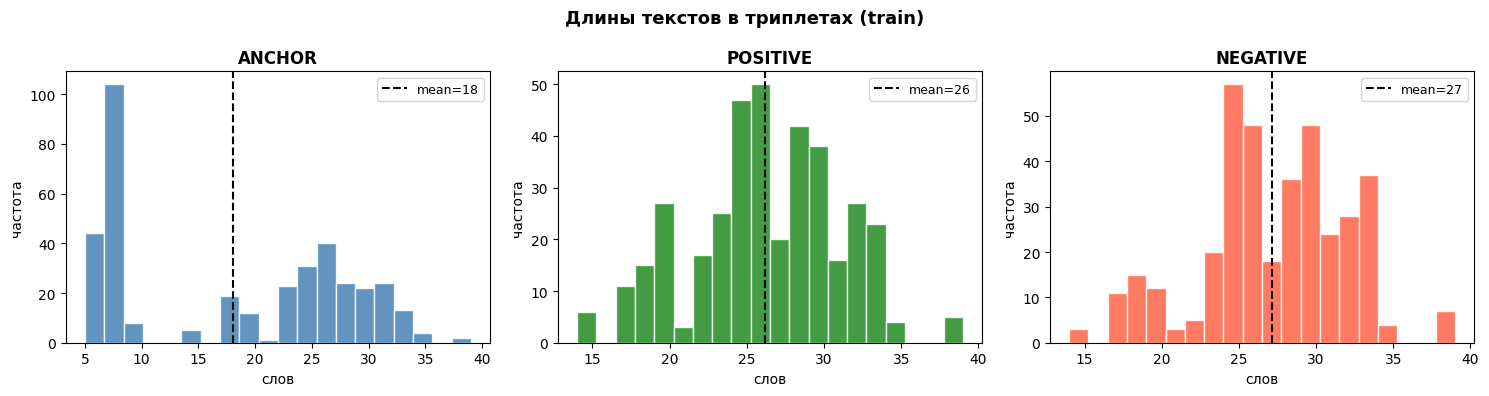

In [16]:
# Статистика длин по каждой роли
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = {"anchor": "steelblue", "positive": "forestgreen", "negative": "tomato"}

for ax, col in zip(axes, ["anchor", "positive", "negative"]):
    lengths = train_df[col].str.split().str.len()
    ax.hist(lengths, bins=20, color=palette[col], edgecolor="white", alpha=0.85)
    ax.axvline(lengths.mean(), color="black", linestyle="--",
               label=f"mean={lengths.mean():.0f}")
    ax.set_title(col.upper(), fontsize=12, fontweight="bold")
    ax.set_xlabel("слов"); ax.set_ylabel("частота")
    ax.legend(fontsize=9)

plt.suptitle("Длины текстов в триплетах (train)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 2.3 Анализ сложности негативов — почему они «трудные»?

Считаем косинусное сходство `sim(anchor, positive)` и `sim(anchor, negative)` на **оригинальной** модели.  
Хорошо подобранный hard negative: его сходство с anchor лишь немного ниже, чем у positive.  
Если разрыв маленький — модели трудно их различить, и она реально учится.

In [17]:
print("Вычисляем сходства с оригинальной моделью...")

anchors   = train_df["anchor"].tolist()
positives = train_df["positive"].tolist()
negatives = train_df["negative"].tolist()

emb_a = model_orig.encode(anchors,   normalize_embeddings=True, show_progress_bar=True)
emb_p = model_orig.encode(positives, normalize_embeddings=True, show_progress_bar=True)
emb_n = model_orig.encode(negatives, normalize_embeddings=True, show_progress_bar=True)

sim_pos = (emb_a * emb_p).sum(axis=1)   # поэлементное скалярное произведение
sim_neg = (emb_a * emb_n).sum(axis=1)
gap     = sim_pos - sim_neg

train_df["sim_pos"] = sim_pos
train_df["sim_neg"] = sim_neg
train_df["gap"]     = gap

print(f"\nsim(anchor, positive)  mean={sim_pos.mean():.3f}  min={sim_pos.min():.3f}  max={sim_pos.max():.3f}")
print(f"sim(anchor, negative)  mean={sim_neg.mean():.3f}  min={sim_neg.min():.3f}  max={sim_neg.max():.3f}")
print(f"gap (pos - neg)        mean={gap.mean():.3f}  min={gap.min():.3f}  max={gap.max():.3f}")
print(f"\nТриплетов где gap < 0.1 (очень трудные): {(gap < 0.1).sum()} ({(gap < 0.1).mean()*100:.0f}%)")
print(f"Триплетов где gap < 0   (false negatives?): {(gap < 0).sum()}")

Вычисляем сходства с оригинальной моделью...


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Batches:   0%|          | 0/12 [00:00<?, ?it/s]


sim(anchor, positive)  mean=0.642  min=0.334  max=0.857
sim(anchor, negative)  mean=0.466  min=0.236  max=0.797
gap (pos - neg)        mean=0.176  min=-0.260  max=0.533

Триплетов где gap < 0.1 (очень трудные): 123 (33%)
Триплетов где gap < 0   (false negatives?): 49


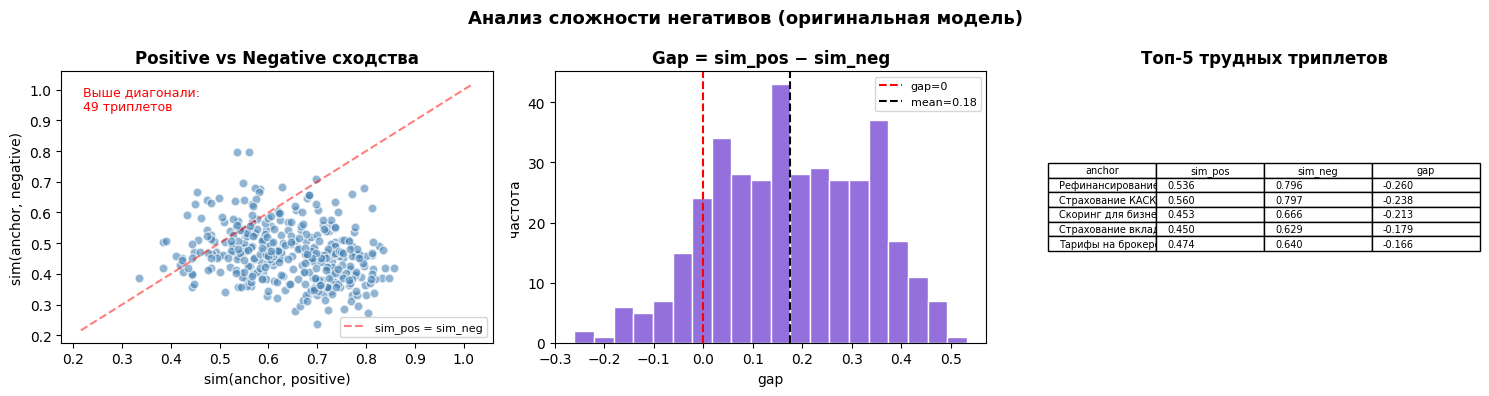

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Scatter: sim_pos vs sim_neg
axes[0].scatter(sim_pos, sim_neg, alpha=0.6, color="steelblue", s=40, edgecolors="white")
lim = [min(sim_pos.min(), sim_neg.min()) - 0.02, 1.02]
axes[0].plot(lim, lim, "r--", alpha=0.5, label="sim_pos = sim_neg")
axes[0].set_xlabel("sim(anchor, positive)"); axes[0].set_ylabel("sim(anchor, negative)")
axes[0].set_title("Positive vs Negative сходства", fontweight="bold")
axes[0].legend(fontsize=8)
# Точки выше диагонали — где модели трудно (negative > positive)
hard = (sim_neg > sim_pos).sum()
axes[0].text(0.05, 0.95, f"Выше диагонали:\n{hard} триплетов",
             transform=axes[0].transAxes, va="top", fontsize=9, color="red")

# Распределение gap
axes[1].hist(gap, bins=20, color="mediumpurple", edgecolor="white")
axes[1].axvline(0,          color="red",   linestyle="--", label="gap=0")
axes[1].axvline(gap.mean(), color="black", linestyle="--", label=f"mean={gap.mean():.2f}")
axes[1].set_title("Gap = sim_pos − sim_neg", fontweight="bold")
axes[1].set_xlabel("gap"); axes[1].set_ylabel("частота")
axes[1].legend(fontsize=8)

# Топ-5 самых трудных триплетов
hardest = train_df.nsmallest(5, "gap")[["anchor", "sim_pos", "sim_neg", "gap"]]
axes[2].axis("off")
tbl = axes[2].table(
    cellText=[
        [r["anchor"][:35]+"...", f"{r['sim_pos']:.3f}", f"{r['sim_neg']:.3f}", f"{r['gap']:.3f}"]
        for _, r in hardest.iterrows()
    ],
    colLabels=["anchor", "sim_pos", "sim_neg", "gap"],
    loc="center", cellLoc="left",
)
tbl.auto_set_font_size(False); tbl.set_fontsize(7)
axes[2].set_title("Топ-5 трудных триплетов", fontweight="bold")

plt.suptitle("Анализ сложности негативов (оригинальная модель)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/stage2_negative_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Показываем самые трудные триплеты вербально
print("TOP-3 ТРУДНЫХ ТРИПЛЕТА (gap наименьший — модели сложнее всего их различить):\n")
for _, row in train_df.nsmallest(3, "gap").iterrows():
    print(f"  ANCHOR   : {row['anchor']}")
    print(f"  POSITIVE : {row['positive'][:110]}")
    print(f"             sim={row['sim_pos']:.3f}")
    print(f"  NEGATIVE : {row['negative'][:110]}")
    print(f"             sim={row['sim_neg']:.3f}  |  gap={row['gap']:.3f}")
    print("  " + "─" * 100)

TOP-3 ТРУДНЫХ ТРИПЛЕТА (gap наименьший — модели сложнее всего их различить):

  ANCHOR   : Рефинансирование потребительского кредита позволяет объединить несколько
кредитов в один и снизить ежемесячный платёж за счёт более низкой ставки
или увеличения срока. Для рефинансирования требуется отсутствие текущих просрочек.
  POSITIVE : Требования к заёмщику: гражданство РФ, возраст от 18 до 70 лет, постоянная
регистрация, стаж на текущем месте 
             sim=0.536
  NEGATIVE : Рефинансирование ипотеки позволяет снизить текущую процентную ставку,
переоформив кредит в другом банке или в 
             sim=0.796  |  gap=-0.260
  ────────────────────────────────────────────────────────────────────────────────────────────────────
  ANCHOR   : Страхование КАСКО является обязательным условием автокредита: автомобиль
страхуется от угона и ущерба на весь срок кредитования. Стоимость КАСКО
включается в полную стоимость кредита (ПСК).
  POSITIVE : Процентная ставка по автокредиту зависит от первонач

## 2.4 Эксперимент А: TripletLoss

**Формула:** `L = max(0, d(a,p) − d(a,n) + margin)`

Явно обучаем: positive должен быть ближе к anchor, чем negative, с зазором `margin`.

In [20]:
if DEVICE == "cpu":
    cfg_triplet = make_cpu_config(
        loss_type=LossType.TRIPLET,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_triplet",
    )
else:
    cfg_triplet = make_gpu_config(
        loss_type=LossType.TRIPLET,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_triplet",
    )

cfg_triplet.triplet_margin          = 0.5
cfg_triplet.early_stopping_patience = EARLY_STOPPING_PATIENCE
cfg_triplet.logging_strategy        = LOG_EVERY

print(f"Loss        : {cfg_triplet.loss_type}")
print(f"Margin      : {cfg_triplet.triplet_margin}")
print(f"Epochs      : {cfg_triplet.num_epochs}")
print(f"EarlyStop   : {cfg_triplet.early_stopping_patience}")
print(f"Logging     : {cfg_triplet.logging_strategy!r}")

Loss        : LossType.TRIPLET
Margin      : 0.5
Epochs      : 10
EarlyStop   : 2
Logging     : 'epoch'


In [21]:
trainer_triplet = EmbeddingTrainer(cfg_triplet)

2026-03-25 09:37:52,591 | INFO | Устройство: cuda
2026-03-25 09:37:52,593 | INFO | GPU: включён bf16
2026-03-25 09:37:52,593 | INFO | Загрузка модели: deepvk/USER-bge-m3
2026-03-25 09:37:52,601 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-25 09:37:55,523 | INFO | Модель загружена. max_seq_length=512


In [22]:
trainer_triplet.train(train_df, eval_df)

2026-03-25 09:37:55,528 | INFO | Подготовка датасета: 376 обучающих строк, loss=LossType.TRIPLET
2026-03-25 09:37:55,542 | INFO | EarlyStopping (eval_loss): patience=2, best→../output/stage2_triplet/best_triplet


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

2026-03-25 09:37:55,691 | INFO | Старт обучения: epochs=10, batch=32, lr=2e-05, device=cuda, early_stop_patience=2, logging=epoch


Epoch,Training Loss,Validation Loss
1,0.273800,0.130876
2,0.078900,0.055148
3,0.029300,0.043126
4,0.011700,0.035233
5,0.004800,0.029170
6,0.001900,0.024550
7,0.000800,0.023290
8,0.000300,0.022787
9,0.000400,0.022837
10,0.000100,0.023039


2026-03-25 09:38:58,739 | INFO | Epoch 1/10 [train] | loss=0.2738 | lr=2.00e-05
2026-03-25 09:39:02,654 | INFO | Epoch 1/10 [eval] | eval_loss=0.1309 | eval_runtime=3.9134 | eval_samples_per_second=24.0200 | eval_steps_per_second=0.7670 | epoch=1.0000
2026-03-25 09:39:02,661 | INFO | Saving model checkpoint to ../output/stage2_triplet/checkpoint-12
2026-03-25 09:39:02,666 | INFO | Save model to ../output/stage2_triplet/checkpoint-12
2026-03-25 09:40:22,382 | INFO | Epoch 2/10 [train] | loss=0.0789 | lr=1.78e-05
2026-03-25 09:40:26,324 | INFO | Epoch 2/10 [eval] | eval_loss=0.0551 | eval_runtime=3.9394 | eval_samples_per_second=23.8620 | eval_steps_per_second=0.7620 | epoch=2.0000
2026-03-25 09:40:26,330 | INFO | Saving model checkpoint to ../output/stage2_triplet/checkpoint-24
2026-03-25 09:40:26,332 | INFO | Save model to ../output/stage2_triplet/checkpoint-24
2026-03-25 09:41:53,335 | INFO | Epoch 3/10 [train] | loss=0.0293 | lr=1.56e-05
2026-03-25 09:41:57,284 | INFO | Epoch 3/10 [e

## 2.5 Эксперимент Б: MNRL (рекомендованный)

**Формула:** `L = -log( exp(sim(aᵢ, pᵢ)/τ) / Σⱼ exp(sim(aᵢ, pⱼ)/τ) )`

In-batch negatives: при `batch_size=B` каждый запрос получает `B-1` негативов бесплатно.  
Колонка `negative` из CSV добавляется как дополнительный hard negative поверх in-batch.

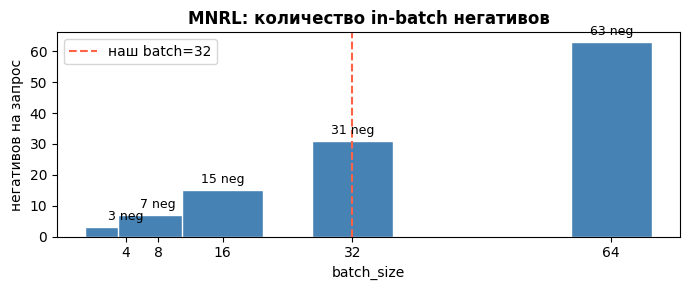

In [23]:
# Визуализируем идею in-batch negatives
batch_sizes = [4, 8, 16, 32, 64]
negatives_per_query = [b - 1 for b in batch_sizes]

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(batch_sizes, negatives_per_query, color="steelblue",
              width=10, edgecolor="white")
ax.bar_label(bars, labels=[f"{n} neg" for n in negatives_per_query],
             padding=3, fontsize=9)
ax.set_xlabel("batch_size"); ax.set_ylabel("негативов на запрос")
ax.set_title("MNRL: количество in-batch негативов", fontweight="bold")
ax.set_xticks(batch_sizes)
cfg_b = cfg_triplet.batch_size
ax.axvline(cfg_b, color="tomato", linestyle="--", label=f"наш batch={cfg_b}")
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
if DEVICE == "cpu":
    cfg_mnrl = make_cpu_config(
        loss_type=LossType.MNRL,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_mnrl",
    )
else:
    cfg_mnrl = make_gpu_config(
        loss_type=LossType.MNRL,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_mnrl",
    )

cfg_mnrl.temperature                = 0.05
cfg_mnrl.early_stopping_patience    = EARLY_STOPPING_PATIENCE
cfg_mnrl.logging_strategy           = LOG_EVERY

print(f"Loss        : {cfg_mnrl.loss_type}")
print(f"Temperature : {cfg_mnrl.temperature}  (scale = {1/cfg_mnrl.temperature:.0f})")
print(f"Epochs      : {cfg_mnrl.num_epochs}")
print(f"EarlyStop   : {cfg_mnrl.early_stopping_patience}")
print(f"Logging     : {cfg_mnrl.logging_strategy!r}")

Loss        : LossType.MNRL
Temperature : 0.05  (scale = 20)
Epochs      : 10
EarlyStop   : 2
Logging     : 'epoch'


In [25]:
trainer_mnrl = EmbeddingTrainer(cfg_mnrl)

2026-03-25 09:53:18,078 | INFO | Устройство: cuda
2026-03-25 09:53:18,079 | INFO | GPU: включён bf16
2026-03-25 09:53:18,080 | INFO | Загрузка модели: deepvk/USER-bge-m3
2026-03-25 09:53:18,085 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-25 09:53:20,976 | INFO | Модель загружена. max_seq_length=512


In [26]:
trainer_mnrl.train(train_df, eval_df)

2026-03-25 09:53:20,981 | INFO | Подготовка датасета: 376 обучающих строк, loss=LossType.MNRL
2026-03-25 09:53:20,995 | INFO | EarlyStopping (eval_loss): patience=2, best→../output/stage2_mnrl/best_mnrl


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

2026-03-25 09:53:21,143 | INFO | Старт обучения: epochs=10, batch=32, lr=2e-05, device=cuda, early_stop_patience=2, logging=epoch


Epoch,Training Loss,Validation Loss
1,1.638300,0.629865
2,0.906400,0.524090
3,0.717500,0.494611
4,0.590200,0.495388
5,0.580100,0.525490


2026-03-25 09:54:16,342 | INFO | Epoch 1/10 [train] | loss=1.6383 | lr=2.00e-05
2026-03-25 09:54:22,146 | INFO | Epoch 1/10 [eval] | eval_loss=0.6299 | eval_runtime=5.8014 | eval_samples_per_second=16.2030 | eval_steps_per_second=0.5170 | epoch=1.0000
2026-03-25 09:54:22,151 | INFO | Saving model checkpoint to ../output/stage2_mnrl/checkpoint-12
2026-03-25 09:54:22,155 | INFO | Save model to ../output/stage2_mnrl/checkpoint-12
2026-03-25 09:55:44,099 | INFO | Epoch 2/10 [train] | loss=0.9064 | lr=1.78e-05
2026-03-25 09:55:49,864 | INFO | Epoch 2/10 [eval] | eval_loss=0.5241 | eval_runtime=5.7624 | eval_samples_per_second=16.3130 | eval_steps_per_second=0.5210 | epoch=2.0000
2026-03-25 09:55:49,870 | INFO | Saving model checkpoint to ../output/stage2_mnrl/checkpoint-24
2026-03-25 09:55:49,874 | INFO | Save model to ../output/stage2_mnrl/checkpoint-24
2026-03-25 09:57:04,926 | INFO | Epoch 3/10 [train] | loss=0.7175 | lr=1.56e-05
2026-03-25 09:57:10,701 | INFO | Epoch 3/10 [eval] | eval_

## 2.6 Эксперимент В: двухэтапный пайплайн TSDAE → MNRL

**Идея:** взять модель, уже адаптированную на доменных текстах (Stage 1, TSDAE),
и дообучить её supervised-методом (MNRL) поверх неё.

```
deepvk/USER-bge-m3
       │
       ▼  Stage 1: TSDAE  (unsupervised, корпус без разметки)
  stage1_tsdae/final
       │
       ▼  Stage 2: MNRL   (supervised, размеченные пары)
  stage2_tsdae_mnrl/final   ← комбо-модель
```

Ожидаемый эффект: TSDAE «разогревает» пространство эмбеддингов под банковскую лексику,
а MNRL дообучает на размеченных парах — лучше, чем каждый этап по отдельности.

In [27]:
# ── Конфигурация Stage 2 поверх TSDAE-модели ────────────────────────────────
# Единственное отличие от cfg_mnrl: model_name → уже обученный TSDAE checkpoint
TSDAE_CHECKPOINT = "../output/stage1_tsdae/best_unsupervised"

if DEVICE == "cpu":
    cfg_tsdae_mnrl = make_cpu_config(
        loss_type=LossType.MNRL,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_tsdae_mnrl",
    )
else:
    cfg_tsdae_mnrl = make_gpu_config(
        loss_type=LossType.MNRL,
        num_epochs=NUM_EPOCHS_SUPERVISED,
        output_dir="../output/stage2_tsdae_mnrl",
    )

cfg_tsdae_mnrl.model_name               = TSDAE_CHECKPOINT
cfg_tsdae_mnrl.temperature              = 0.05
cfg_tsdae_mnrl.early_stopping_patience  = EARLY_STOPPING_PATIENCE
cfg_tsdae_mnrl.logging_strategy         = LOG_EVERY

print("Двухэтапный пайплайн TSDAE → MNRL:")
print(f"  Базовая модель  : {cfg_tsdae_mnrl.model_name}")
print(f"  Loss            : {cfg_tsdae_mnrl.loss_type}")
print(f"  Epochs          : {cfg_tsdae_mnrl.num_epochs}")
print(f"  EarlyStop       : {cfg_tsdae_mnrl.early_stopping_patience}")
print(f"  Logging         : {cfg_tsdae_mnrl.logging_strategy!r}")

Двухэтапный пайплайн TSDAE → MNRL:
  Базовая модель  : ../output/stage1_tsdae/best_unsupervised
  Loss            : LossType.MNRL
  Epochs          : 10
  EarlyStop       : 2
  Logging         : 'epoch'


In [ ]:
trainer_tsdae_mnrl = EmbeddingTrainer(cfg_tsdae_mnrl)
trainer_tsdae_mnrl.train(train_df, eval_df)
print("Двухэтапный пайплайн завершён. Модель сохранена: ../output/stage2_tsdae_mnrl/best_mnrl")

2026-03-25 10:04:01,232 | INFO | Устройство: cuda
2026-03-25 10:04:01,234 | INFO | GPU: включён bf16
2026-03-25 10:04:01,234 | INFO | Загрузка модели: ../output/stage1_tsdae/best_unsupervised
2026-03-25 10:04:01,240 | INFO | Load pretrained SentenceTransformer: ../output/stage1_tsdae/best_unsupervised
2026-03-25 10:04:07,536 | INFO | Модель загружена. max_seq_length=512
2026-03-25 10:04:07,537 | INFO | Подготовка датасета: 376 обучающих строк, loss=LossType.MNRL
2026-03-25 10:04:07,554 | INFO | EarlyStopping (eval_loss): patience=2, best→../output/stage2_tsdae_mnrl/best_mnrl


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

2026-03-25 10:04:07,710 | INFO | Старт обучения: epochs=10, batch=32, lr=2e-05, device=cuda, early_stop_patience=2, logging=epoch


Epoch,Training Loss,Validation Loss
1,1.644800,0.618702
2,0.914800,0.531956


2026-03-25 10:05:08,780 | INFO | Epoch 1/10 [train] | loss=1.6448 | lr=2.00e-05
2026-03-25 10:05:15,457 | INFO | Epoch 1/10 [eval] | eval_loss=0.6187 | eval_runtime=6.6742 | eval_samples_per_second=14.0840 | eval_steps_per_second=0.4490 | epoch=1.0000
2026-03-25 10:05:15,461 | INFO | Saving model checkpoint to ../output/stage2_tsdae_mnrl/checkpoint-12
2026-03-25 10:05:15,466 | INFO | Save model to ../output/stage2_tsdae_mnrl/checkpoint-12
2026-03-25 10:06:40,097 | INFO | Epoch 2/10 [train] | loss=0.9148 | lr=1.78e-05
2026-03-25 10:06:46,801 | INFO | Epoch 2/10 [eval] | eval_loss=0.5320 | eval_runtime=6.7017 | eval_samples_per_second=14.0260 | eval_steps_per_second=0.4480 | epoch=2.0000
2026-03-25 10:06:46,807 | INFO | Saving model checkpoint to ../output/stage2_tsdae_mnrl/checkpoint-24
2026-03-25 10:06:46,810 | INFO | Save model to ../output/stage2_tsdae_mnrl/checkpoint-24
2026-03-25 10:08:13,494 | INFO | Epoch 3/10 [train] | loss=0.7142 | lr=1.56e-05


---
# Оценка качества: сравниваем все модели

Строим retrieval-тест из наших триплетов:  
- `queries`  = все anchors  
- `corpus`   = все positives + все negatives  
- `qrels`    = anchor → [его positive]

## 3.1 Формируем eval set

In [31]:
# Объединяем train + eval для построения корпуса оценки
all_triplets_df = pd.concat([train_df, eval_df], ignore_index=True)

queries, corpus, qrels = build_evaluation_set(
    triplets_df=all_triplets_df,
    n_queries=len(all_triplets_df),
    seed=42,
)

evaluator = RetrievalEvaluator(
    queries=queries,
    corpus=corpus,
    qrels=qrels,
    ks=(1, 3, 5, 10),
)

print(f"Запросов : {len(queries)}")
print(f"Корпус   : {len(corpus)} документов")

2026-03-24 19:12:55,369 | INFO | Evaluation set: 75 запросов, 72 документов в корпусе
2026-03-24 19:12:55,370 | INFO | RetrievalEvaluator: 75 запросов, 72 документов


Запросов : 75
Корпус   : 72 документов


## 3.2 Оцениваем все 4 модели

In [32]:
models_to_eval = {
    "baseline":       MODEL_NAME,
    "tsdae":          "../output/stage1_tsdae/final",
    "triplet":        "../output/stage2_triplet/final",
    "mnrl":           "../output/stage2_mnrl/final",
    "tsdae+mnrl":     "../output/stage2_tsdae_mnrl/final",   # двухэтапный пайплайн
}

results = {}
for alias, path in models_to_eval.items():
    print(f"\nОцениваем: {alias} ({path})")
    results[alias] = evaluator.evaluate(path, batch_size=32)

print("\nОценка завершена.")

2026-03-24 19:12:58,330 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3



Оцениваем: baseline (deepvk/USER-bge-m3)


2026-03-24 19:12:58,563 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:12:58,596 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/modules.json "HTTP/1.1 200 OK"
2026-03-24 19:12:58,759 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:12:58,797 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config_sentence_transformers.json "HTTP/1.1 200 OK"
2026-03-24 19:12:58,964 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:12:58,999 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-03-24 19:13:00,278 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:13:00,311 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 19:13:00,468 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:13:00,502 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 19:13:00,663 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-03-24 19:13:00,825 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge

...

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

2026-03-24 19:13:37,232 | INFO | Кодирование запросов (75)...


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

2026-03-24 19:13:38,110 | INFO | Оценка ../output/stage2_tsdae_mnrl/final | R@1=1.0000 R@5=1.0000 R@10=1.0000 MRR@10=1.0000 NDCG@10=1.0000



Оценка завершена.


In [33]:
metric_cols = ["Recall@1", "Recall@3", "Recall@5", "Recall@10",
               "MRR@10", "NDCG@10", "MAP@10"]

comparison_df = pd.DataFrame(
    {alias: m.to_dict() for alias, m in results.items()}
).T[metric_cols]

# Прирост относительно baseline
delta_df = comparison_df.subtract(comparison_df.loc["baseline"]).round(4)

print("Абсолютные значения метрик:")
display(comparison_df.style
    .highlight_max(axis=0, color="#c6efce")
    .highlight_min(axis=0, color="#ffc7ce")
    .format("{:.4f}"))

print("\nПрирост относительно baseline (Δ):")
display(delta_df.drop(index="baseline").style
    .background_gradient(cmap="RdYlGn", axis=None, vmin=-0.15, vmax=0.15)
    .format("{:+.4f}"))

Абсолютные значения метрик:


,Recall@1,Recall@3,Recall@5,Recall@10,MRR@10,NDCG@10,MAP@10
baseline,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
tsdae,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
triplet,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
mnrl,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
tsdae+mnrl,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



Прирост относительно baseline (Δ):


,Recall@1,Recall@3,Recall@5,Recall@10,MRR@10,NDCG@10,MAP@10
tsdae,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
triplet,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
mnrl,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
tsdae+mnrl,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000


## 3.3 Визуализация

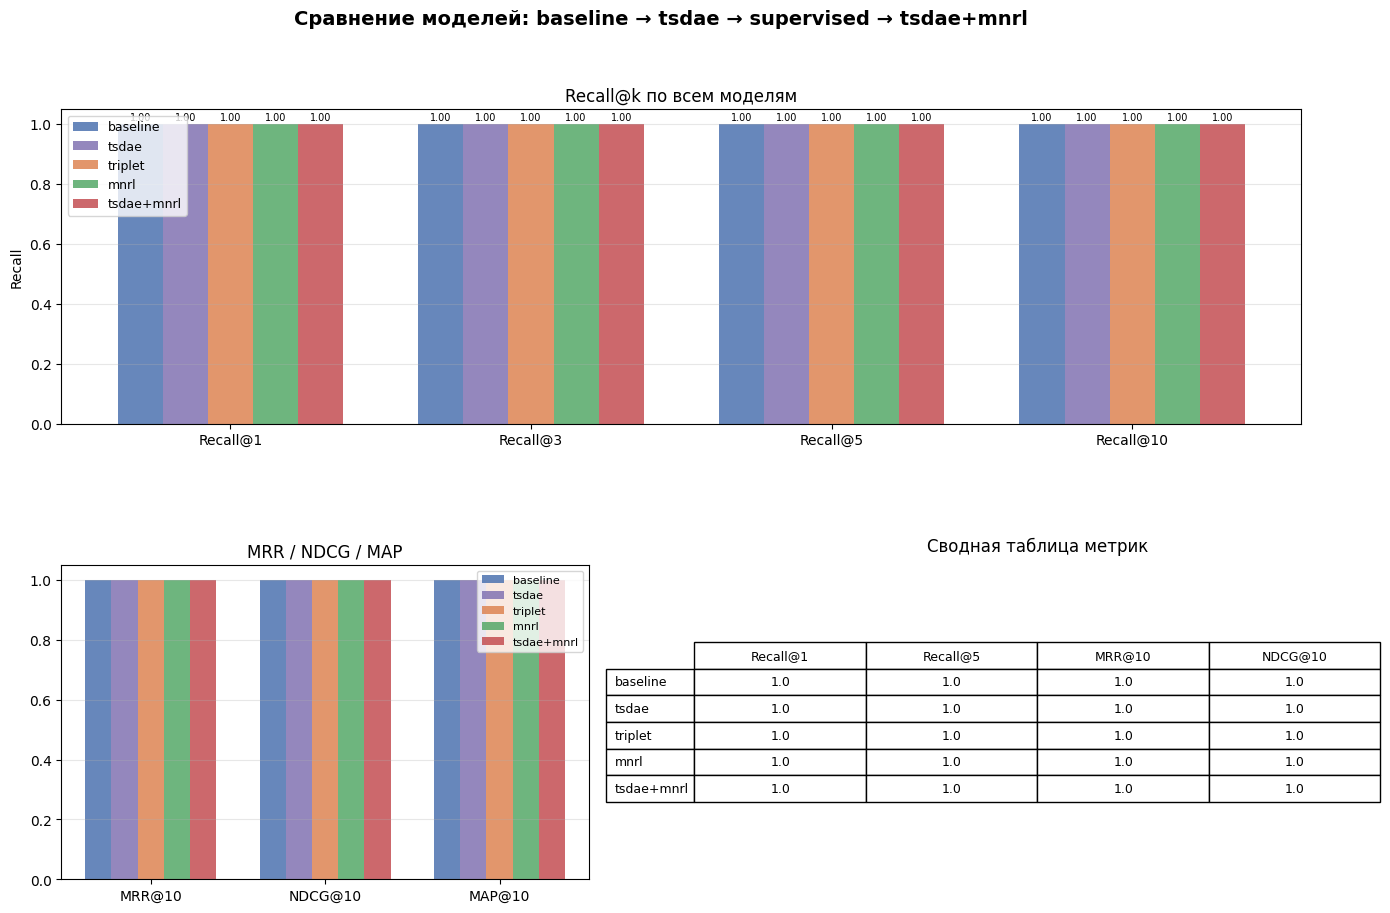

In [34]:
colors = ["#4C72B0", "#8172B2", "#DD8452", "#55A868", "#C44E52"]
# baseline   tsdae       triplet     mnrl        tsdae+mnrl
aliases = comparison_df.index.tolist()

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── Bar-chart: Recall@k ──────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
recall_cols = [c for c in comparison_df.columns if c.startswith("Recall@")]
x = range(len(recall_cols))
width = 0.15
for j, (alias, color) in enumerate(zip(aliases, colors)):
    vals = [comparison_df.loc[alias, c] for c in recall_cols]
    offset = (j - len(aliases)/2 + 0.5) * width
    bars = ax1.bar([xi + offset for xi in x], vals, width, label=alias, color=color, alpha=0.85)
    for bar in bars:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=7)

ax1.set_xticks(list(x))
ax1.set_xticklabels(recall_cols)
ax1.set_ylabel("Recall")
ax1.set_title("Recall@k по всем моделям")
ax1.legend(loc="upper left", fontsize=9)
ax1.set_ylim(0, 1.05)
ax1.grid(axis="y", alpha=0.3)

# ── Bar-chart: MRR / NDCG / MAP ──────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
other_cols = ["MRR@10", "NDCG@10", "MAP@10"]
x2 = range(len(other_cols))
for j, (alias, color) in enumerate(zip(aliases, colors)):
    vals = [comparison_df.loc[alias, c] for c in other_cols]
    offset = (j - len(aliases)/2 + 0.5) * width
    ax2.bar([xi + offset for xi in x2], vals, width, label=alias, color=color, alpha=0.85)
ax2.set_xticks(list(x2))
ax2.set_xticklabels(other_cols)
ax2.set_title("MRR / NDCG / MAP")
ax2.legend(fontsize=8)
ax2.set_ylim(0, 1.05)
ax2.grid(axis="y", alpha=0.3)

# ── Таблица числовых значений ─────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 1])
ax3.axis("off")
tbl_data = comparison_df[["Recall@1", "Recall@5", "MRR@10", "NDCG@10"]].round(3)
tbl = ax3.table(
    cellText=tbl_data.values,
    rowLabels=tbl_data.index,
    colLabels=tbl_data.columns,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.3, 1.6)
ax3.set_title("Сводная таблица метрик", pad=10)

plt.suptitle("Сравнение моделей: baseline → tsdae → supervised → tsdae+mnrl", fontsize=14, fontweight="bold")
plt.savefig("../output/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.4 Качественный анализ: что именно изменилось в retrieval

In [35]:
# Строим корпус из stage1 (чанки) для демонстрации живого поиска
corpus_df_reload = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")
corpus_texts = corpus_df_reload["sentence"].tolist()

# Тестовые запросы из eval триплетов
test_queries = eval_df["anchor"].head(4).tolist()
ground_truth = eval_df["positive"].head(4).tolist()

def search(model_or_path, queries, corpus, top_k=3):
    if isinstance(model_or_path, str):
        m = SentenceTransformer(model_or_path)
    else:
        m = model_or_path
    c_emb = m.encode(corpus, normalize_embeddings=True, show_progress_bar=False)
    results = []
    for q in queries:
        q_emb = m.encode([q], normalize_embeddings=True)
        sims  = (q_emb @ c_emb.T)[0]
        top   = np.argsort(sims)[::-1][:top_k]
        results.append([(corpus[i], float(sims[i])) for i in top])
    return results

res_baseline = search(MODEL_NAME,                        test_queries, corpus_texts)
res_mnrl     = search("../output/stage2_tsdae_mnrl/final",     test_queries, corpus_texts)

print("=" * 100)
for i, (query, gt) in enumerate(zip(test_queries, ground_truth)):
    print(f"\nЗАПРОС: {query}")
    print(f"ЭТАЛОН: {gt[:95]}...\n")

    print(f"  {'BASELINE':^46}  {'MNRL (дообученная)':^46}")
    print(f"  {'─'*46}  {'─'*46}")
    for rank, (b, m) in enumerate(zip(res_baseline[i], res_mnrl[i]), 1):
        mark_b = "✓" if gt[:40] in b[0] else " "
        mark_m = "✓" if gt[:40] in m[0] else " "
        print(f"  [{rank}]{mark_b} ({b[1]:.3f}) {b[0][:38]:<38}  [{rank}]{mark_m} ({m[1]:.3f}) {m[0][:38]:<38}")
    print("=" * 100)

2026-03-24 19:14:39,450 | INFO | Use pytorch device_name: cuda:0
2026-03-24 19:14:39,451 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-24 19:14:39,690 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:14:39,732 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/modules.json "HTTP/1.1 200 OK"
2026-03-24 19:14:39,892 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:14:39,936 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config_sentence_transformers.json "HTTP/1.1 200 OK"
2026-03-24 19:14:40,108 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-03-24 19:14:41,484 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:14:41,520 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 19:14:41,678 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 19:14:41,719 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 19:14:41,885 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-03-24 19:14:42,056 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]


ЗАПРОС: Требования к Индивидуальный инвестиционный счёт (ИИС) даёт
ЭТАЛОН: Индивидуальный инвестиционный счёт (ИИС) даёт право на налоговый вычет в размере 13% от суммы в...

                     BASELINE                                   MNRL (дообученная)              
  ──────────────────────────────────────────────  ──────────────────────────────────────────────
  [1]✓ (0.684) Индивидуальный инвестиционный счёт (ИИ  [1]✓ (0.879) Индивидуальный инвестиционный счёт (ИИ
  [2]  (0.584) Инвестиционное страхование жизни (ИСЖ)  [2]  (0.360) Инвестиционное страхование жизни (ИСЖ)
  [3]  (0.558) Расчётный счёт для юридических лиц и И  [3]  (0.233) Расчётный счёт для юридических лиц и И

ЗАПРОС: В чём особенности Облигации федерального займа (ОФЗ) ?
ЭТАЛОН: Облигации федерального займа (ОФЗ) — государственные ценные бумаги с фиксированным купонным дох...

                     BASELINE                                   MNRL (дообученная)              
  ──────────────────────────────────────

## 3.5 Как изменились сходства после обучения (gap анализ)

2026-03-24 19:15:09,261 | INFO | Use pytorch device_name: cuda:0
2026-03-24 19:15:09,262 | INFO | Load pretrained SentenceTransformer: ../output/stage2_tsdae_mnrl/final


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

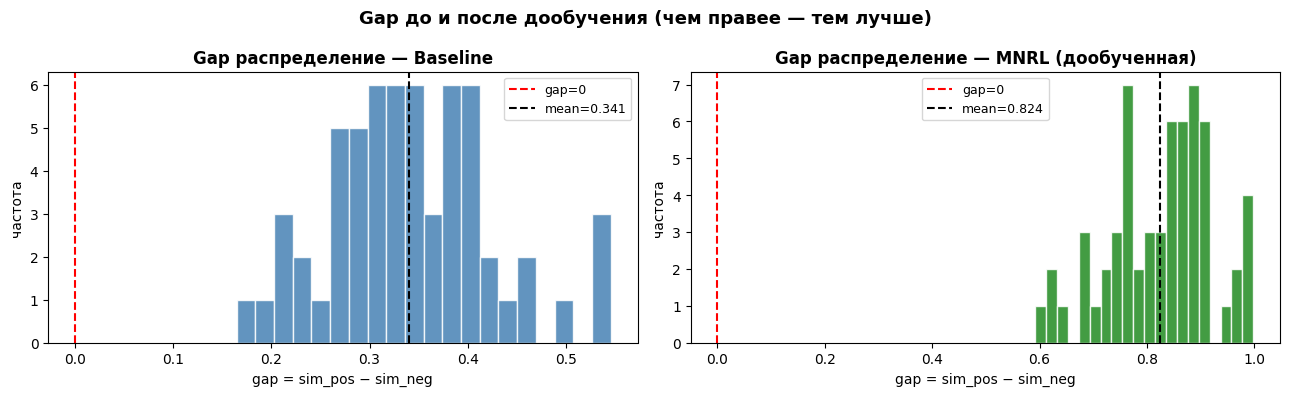

Baseline  gap: mean=0.341  |  gap<0: 0 триплетов
MNRL      gap: mean=0.824  |  gap<0: 0 триплетов


In [36]:
model_mnrl = SentenceTransformer("../output/stage2_tsdae_mnrl/final")

emb_a_ft = model_mnrl.encode(anchors,   normalize_embeddings=True)
emb_p_ft = model_mnrl.encode(positives, normalize_embeddings=True)
emb_n_ft = model_mnrl.encode(negatives, normalize_embeddings=True)

sim_pos_ft = (emb_a_ft * emb_p_ft).sum(axis=1)
sim_neg_ft = (emb_a_ft * emb_n_ft).sum(axis=1)
gap_ft     = sim_pos_ft - sim_neg_ft

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (gap_vals, label, color) in zip(axes, [
    (gap,    "Baseline",      "steelblue"),
    (gap_ft, "MNRL (дообученная)", "forestgreen"),
]):
    ax.hist(gap_vals, bins=20, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(0,              color="red",   linestyle="--", label="gap=0")
    ax.axvline(gap_vals.mean(),color="black", linestyle="--",
               label=f"mean={gap_vals.mean():.3f}")
    ax.set_title(f"Gap распределение — {label}", fontweight="bold")
    ax.set_xlabel("gap = sim_pos − sim_neg")
    ax.set_ylabel("частота")
    ax.legend(fontsize=9)

plt.suptitle("Gap до и после дообучения (чем правее — тем лучше)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/gap_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Baseline  gap: mean={gap.mean():.3f}  |  gap<0: {(gap<0).sum()} триплетов")
print(f"MNRL      gap: mean={gap_ft.mean():.3f}  |  gap<0: {(gap_ft<0).sum()} триплетов")

---
## Итоги

| Этап | Данные | Что обучилось | Когда использовать |
|------|--------|---------------|--------------------|
| **TSDAE** | `stage1_tsdae/corpus.csv` (75 чанков, без разметки) | Доменная лексика | Всегда — даже без лейблов |
| **TripletLoss** | `генерация из stage1_tsdae/corpus.csv` | Явный зазор pos/neg | Малые данные, интерпретируемость |
| **MNRL** | `генерация из stage1_tsdae/corpus.csv` | In-batch negatives | **Рекомендован** — лучшее качество |

**Лучшая практика для банка:**  
1. TSDAE на всех доступных чанках → сохраняем модель  
2. MNRL на триплетах (anchor=запрос, positive=чанк, negative=BM25-hard из смежной темы)  
3. После 1-й эпохи заменить BM25-негативы на embedding-hard (ANCE)